# Proyecto 2 · Análisis exploratorio visual de los frames
## Variables visuales extraídas de los 200 clips

**CC3084 – Ciencia de Datos · Semestre II 2026**

Se muestrearon **10 frames por clip** (2,000 frames) y de cada uno se extrajeron
variables cuantitativas sin usar etiquetas: brillo, contraste, saturación, cobertura
de cancha (`green_ratio`), densidad de bordes, movimiento respecto al frame muestreado
anterior y un conteo de blobs de jugador. Este cuaderno estudia esas variables con
estadística descriptiva y gráficos exploratorios.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('../data/frame_features.csv')
print('Observaciones (frames):', len(df))
print('Variables:', df.shape[1])
print('Faltantes:', int(df.isna().sum().sum()), '| filas duplicadas:', int(df.duplicated().sum()))
print('Frames por partido:', df.match_id.value_counts().unique())
df.dtypes

Observaciones (frames): 2000
Variables: 12
Faltantes: 0 | filas duplicadas: 0
Frames por partido: [100]


file             object
match_id         object
clip_idx          int64
frame_pos         int64
time_s          float64
brightness      float64
contrast        float64
saturation      float64
green_ratio     float64
edge_density    float64
player_count      int64
motion          float64
dtype: object

## 1. Tipos de variables y tratamiento de valores faltantes

- **Cuantitativas continuas:** brightness, contrast, saturation, green_ratio,
  edge_density, motion.
- **Cuantitativa discreta:** player_count (proxy por blobs).
- **Categóricas / identificadores:** file, match_id (20 partidos), clip_idx, frame_pos.

El CSV no tiene celdas vacías, pero `motion` vale **0 en el primer frame de cada clip**
(200 frames) porque no existe un frame anterior con el cual compararlo. Ese 0 no es una
medición real sino un **faltante estructural**: se reemplaza por `NaN` para que no
sesgue la media ni aparezca como outlier. No se imputa porque no hay información para
estimarlo.

In [2]:
print('Frames con motion == 0:', int((df.motion == 0).sum()),
      '| todos en frame_pos 0:', bool((df[df.motion == 0].frame_pos == 0).all()))
df.loc[df.motion == 0, 'motion'] = np.nan

num = ['brightness','contrast','saturation','green_ratio','edge_density','motion','player_count']
resumen = df[num].describe().T
resumen['asimetría'] = df[num].skew()
resumen.round(3)

Frames con motion == 0: 200 | todos en frame_pos 0: True


,count,mean,std,min,25%,50%,75%,max,asimetría
brightness,2000.0,104.696,14.836,64.540,98.858,106.465,113.115,153.050,-0.307
contrast,2000.0,45.378,6.506,27.810,40.680,45.760,49.665,69.670,0.227
saturation,2000.0,100.307,16.943,59.840,87.018,99.775,111.982,147.490,0.171
green_ratio,2000.0,0.604,0.122,0.129,0.515,0.612,0.691,0.913,-0.140
edge_density,2000.0,0.068,0.019,0.024,0.055,0.067,0.081,0.134,0.204
motion,1800.0,24.116,7.044,4.139,19.605,23.693,28.143,57.583,0.532
player_count,2000.0,63.378,23.720,15.000,48.000,60.000,74.000,199.000,1.345


## 2. Distribución de las variables cuantitativas (histogramas)

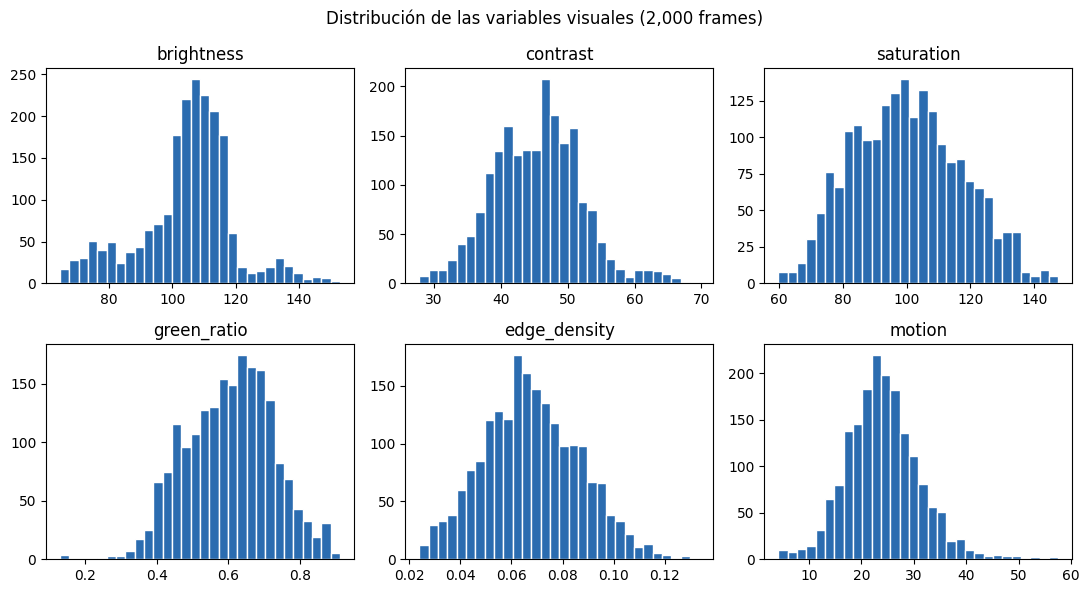

In [3]:
fig, axs = plt.subplots(2, 3, figsize=(11, 6))
for ax, col in zip(axs.ravel(), ['brightness','contrast','saturation','green_ratio','edge_density','motion']):
    ax.hist(df[col].dropna(), bins=30, color='#2b6cb0', edgecolor='white')
    ax.set_title(col)
fig.suptitle('Distribución de las variables visuales (2,000 frames)')
fig.tight_layout(); fig.savefig('../outputs/08_feature_histograms.png'); plt.show()

**Lectura.** `green_ratio` (cobertura de cancha) es alto en la mayoría de frames
(mediana 0.61, cámara táctica que enmarca el campo) con una cola hacia valores bajos:
primeros planos, repeticiones o tomas de gradas. El brillo se concentra en un rango
medio con asimetría negativa (frames oscuros); `motion` tiene una cola a la derecha
por los cambios de plano. `player_count` por blobs es muy asimétrico (asimetría 1.35,
máximo 199): no es un conteo creíble de jugadores (se compara con YOLO en el
cuaderno 03).

## 3. Diagramas de caja y detección de outliers

Las variables tienen escalas muy distintas (`edge_density` ≈ 0.07, `brightness` ≈ 105),
así que se grafican **estandarizadas (z-score)** para poder compararlas en un mismo eje.
Los outliers se cuentan con la regla de **1.5 × IQR**.

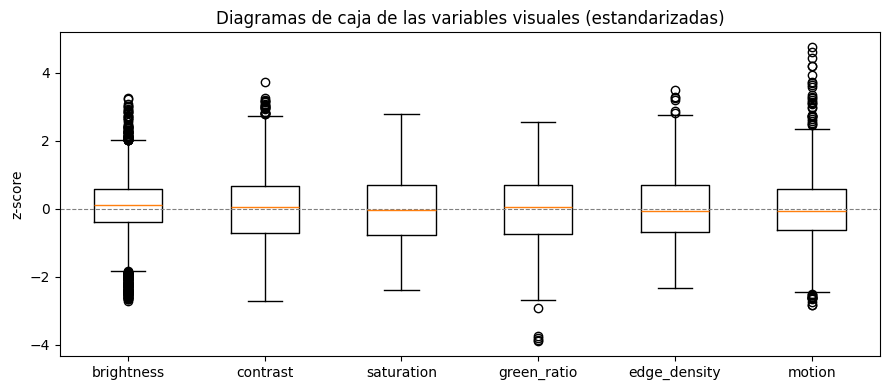

,bajos,altos,% del total
brightness,136.0,63.0,10.0
contrast,0.0,21.0,1.0
saturation,0.0,0.0,0.0
green_ratio,5.0,0.0,0.2
edge_density,0.0,6.0,0.3
motion,13.0,29.0,2.3
player_count,0.0,76.0,3.8


In [4]:
cols = ['brightness','contrast','saturation','green_ratio','edge_density','motion']
z = (df[cols] - df[cols].mean()) / df[cols].std()
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([z[col].dropna() for col in cols], tick_labels=cols, showfliers=True)
ax.axhline(0, color='grey', lw=0.8, ls='--')
ax.set(title='Diagramas de caja de las variables visuales (estandarizadas)', ylabel='z-score')
fig.tight_layout(); fig.savefig('../outputs/09_feature_boxplots.png'); plt.show()

def iqr_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); lim = 1.5 * (q3 - q1)
    return pd.Series({'bajos': int((s < q1 - lim).sum()), 'altos': int((s > q3 + lim).sum()),
                      '% del total': round(((s < q1 - lim) | (s > q3 + lim)).mean() * 100, 1)})

df[num].apply(iqr_outliers).T

In [5]:
# Frames atípicos por baja cobertura de cancha (posibles repeticiones / primeros planos)
p5 = df.green_ratio.quantile(0.05)
bajo = df.green_ratio < p5
print(f'Frames con green_ratio < percentil 5 ({p5:.3f}):', int(bajo.sum()))
pd.DataFrame({'green_ratio < p5': df[bajo][num].mean(),
              'resto de frames': df[~bajo][num].mean()}).round(3)

Frames con green_ratio < percentil 5 (0.408): 100


,green_ratio < p5,resto de frames
brightness,79.244,106.036
contrast,49.444,45.164
saturation,87.899,100.960
green_ratio,0.362,0.617
edge_density,0.072,0.068
motion,25.261,24.056
player_count,58.210,63.650


Los 100 frames con menos cancha son **mucho más oscuros** (brillo 79 frente a 106), con
**más contraste** (49 frente a 45) y ligeramente más bordes: coherente con primeros
planos, tomas de gradas y repeticiones. `brightness` es la variable con más outliers
(199 por IQR, en su mayoría bajos) por la misma razón, y `player_count` acumula 76
outliers altos por el ruido del método de blobs.

**Decisión:** los outliers **no se eliminan**. Son tomas reales del video y marcan los
momentos donde la detección de pases no es viable; en la fase de modelado conviene
**filtrarlos con un umbral de `green_ratio`** en lugar de borrarlos del análisis.

## 4. Correlación entre variables visuales

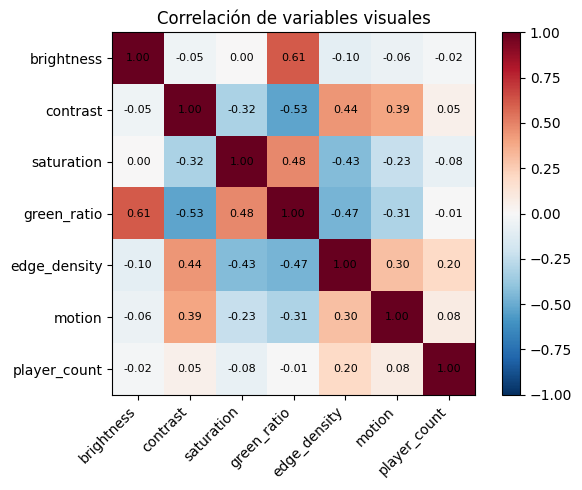

In [6]:
corr = df[num].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=45, ha='right')
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, fraction=0.046); ax.set_title('Correlación de variables visuales')
fig.tight_layout(); fig.savefig('../outputs/10_feature_correlation.png'); plt.show()

**Hallazgos.**

- `green_ratio` vs `brightness` (**+0.61**): la máscara de color detecta menos césped en
  frames oscuros; la cobertura depende de la iluminación del estadio.
- `green_ratio` vs `contrast` (**−0.53**) y vs `edge_density` (**−0.47**): a más cancha
  visible, escena más limpia. `green_ratio` separa las tomas de juego abierto (útiles
  para detectar pases) de las tomas cerradas.
- `contrast` vs `edge_density` (**+0.44**): ambas miden el detalle de la escena.
- `player_count` por blobs casi no correlaciona con nada (|r| ≤ 0.20), otra señal de
  que es una medida ruidosa.

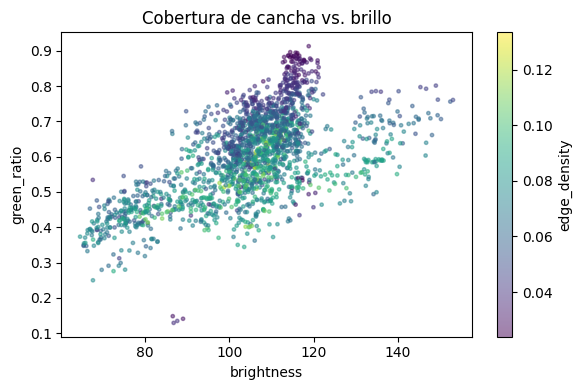

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
sc = ax.scatter(df.brightness, df.green_ratio, c=df.edge_density, s=6, alpha=0.5, cmap='viridis')
ax.set(xlabel='brightness', ylabel='green_ratio', title='Cobertura de cancha vs. brillo')
fig.colorbar(sc, label='edge_density')
fig.tight_layout(); fig.savefig('../outputs/18_green_brightness_scatter.png'); plt.show()

La dispersión confirma la relación: los frames oscuros (brillo < 80) tienen poca cancha
detectada y más bordes (color claro). Es un efecto combinado de iluminación y de tomas
cerradas que el detector deberá manejar.

## 5. Variación entre partidos (variable categórica `match_id`)

match_id,0a2d9b,cd987c,55c9d1,0bfacc,ec783a,c01561,4b770a,538438,744b27,2e57b9,798b45,08fd33,d82e7a,573e61,42ba34,40cd38,a9f16c,121364,54745b,e624c9
frames,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000,100.000
green_mediana,0.417,0.460,0.473,0.502,0.541,0.547,0.571,0.574,0.583,0.617,0.628,0.645,0.648,0.648,0.672,0.680,0.682,0.692,0.762,0.809
brillo_medio,87.014,82.175,95.902,106.912,96.828,121.594,94.072,103.799,95.207,104.648,101.824,111.195,128.739,102.283,111.817,100.788,112.202,106.387,117.065,113.472
proporción (%),5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000


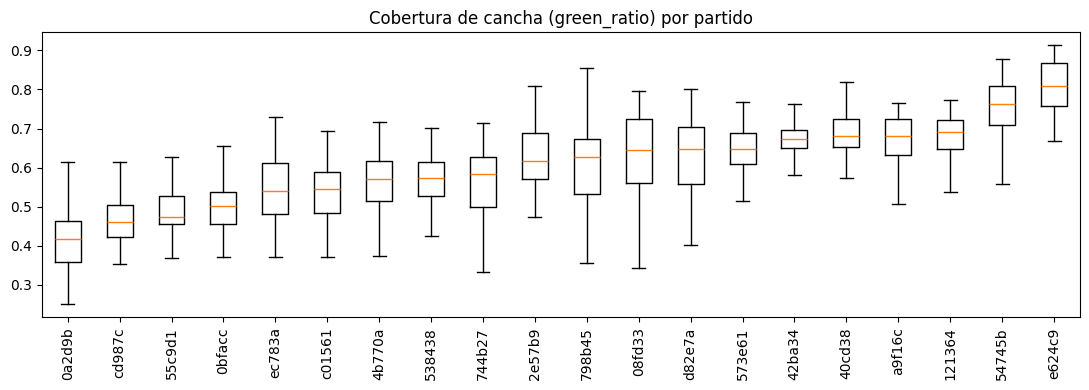

Correlación entre partidos (mediana green vs brillo medio): 0.62


In [8]:
por_partido = df.groupby('match_id').agg(frames=('file', 'size'),
                                          green_mediana=('green_ratio', 'median'),
                                          brillo_medio=('brightness', 'mean')).round(3)
por_partido['proporción (%)'] = (por_partido.frames / len(df) * 100).round(1)
display(por_partido.sort_values('green_mediana').T)

order = por_partido.sort_values('green_mediana').index
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot([df[df.match_id==m].green_ratio for m in order], tick_labels=order, showfliers=False)
ax.set_title('Cobertura de cancha (green_ratio) por partido')
ax.tick_params(axis='x', rotation=90)
fig.tight_layout(); fig.savefig('../outputs/11_greenratio_by_match.png'); plt.show()
print('Correlación entre partidos (mediana green vs brillo medio):',
      round(por_partido.green_mediana.corr(por_partido.brillo_medio), 2))

Cada partido aporta el mismo número de frames (100, el 5 %), así que la muestra está
**balanceada por partido**. Sin embargo, la cobertura de cancha **varía mucho entre
partidos**: la mediana va de **0.42** (`0a2d9b`) a **0.81** (`e624c9`). Esa diferencia
acompaña a la iluminación: entre partidos, la mediana de cobertura y el brillo medio
correlacionan con r = 0.62 (además del tono del césped de cada estadio). Para un
detector esto implica **normalizar por partido** (o usar umbrales de color adaptativos)
en lugar de un umbral fijo.